In [1]:
from pathlib import Path
import pandas as pd

paths = [Path("data/telco_churn.csv"), Path("../data/telco_churn.csv")]
data_path = next((path for path in paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError(f"CSV not found. Notebook is running from: {Path.cwd()}")

print(f"Using: {data_path.resolve()}")
df = pd.read_csv(data_path)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
display(df.head())

Using: C:\Users\ADEDEJI PRECIOUS\Desktop\churn-capacity-study\data\telco_churn.csv
Rows: 7,043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing"))

print("\nChurn counts:")
display(df["Churn"].value_counts())

print(f"\nOverall churn rate: {(df['Churn'] == 'Yes').mean():.1%}")
print("Blank TotalCharges:", df["TotalCharges"].astype(str).str.strip().eq("").sum())

Duplicate customer IDs: 0

Missing values:


,missing
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Overall churn rate: 26.5%
Blank TotalCharges: 11


In [3]:
blank_charges = df["TotalCharges"].astype(str).str.strip().eq("")

display(
    df.loc[
        blank_charges,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [4]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

zero_tenure_blanks = df["TotalCharges"].isna() & df["tenure"].eq(0)
df.loc[zero_tenure_blanks, "TotalCharges"] = 0

print("Remaining missing TotalCharges:", df["TotalCharges"].isna().sum())
print("TotalCharges data type:", df["TotalCharges"].dtype)

Remaining missing TotalCharges: 0
TotalCharges data type: float64


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Clean TotalCharges: the 11 blank entries belong to zero-tenure customers
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)
df.loc[df["TotalCharges"].isna() & df["tenure"].eq(0), "TotalCharges"] = 0

# Keep customerID out: it identifies customers but should not predict churn
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

prep = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_cols),
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

model = Pipeline([
    ("prep", prep),
    ("logistic", LogisticRegression(max_iter=1000)),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
model.fit(X_train, y_train)
scores = model.predict_proba(X_test)[:, 1]

print(f"Test ROC-AUC: {roc_auc_score(y_test, scores):.3f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, scores):.3f}")
print(f"Churn rate in test set: {y_test.mean():.1%}")

results = []
for capacity in (0.10, 0.20):
    n_contact = int(np.ceil(capacity * len(y_test)))
    selected = y_test.iloc[np.argsort(-scores)[:n_contact]]
    precision = selected.mean()
    results.append({
        "Contact capacity": f"Top {capacity:.0%}",
        "Customers contacted": n_contact,
        "Churners found": int(selected.sum()),
        "Share of churners found": f"{selected.sum() / y_test.sum():.1%}",
        "Churn rate in contact list": f"{precision:.1%}",
        "Random-list churn rate": f"{y_test.mean():.1%}",
        "Lift vs random": f"{precision / y_test.mean():.2f}×",
    })

display(pd.DataFrame(results))

Test ROC-AUC: 0.847
Test PR-AUC:  0.638
Churn rate in test set: 26.5%


,Contact capacity,Customers contacted,Churners found,Share of churners found,Churn rate in contact list,Random-list churn rate,Lift vs random
0,Top 10%,177,131,28.1%,74.0%,26.5%,2.79×
1,Top 20%,353,235,50.3%,66.6%,26.5%,2.51×


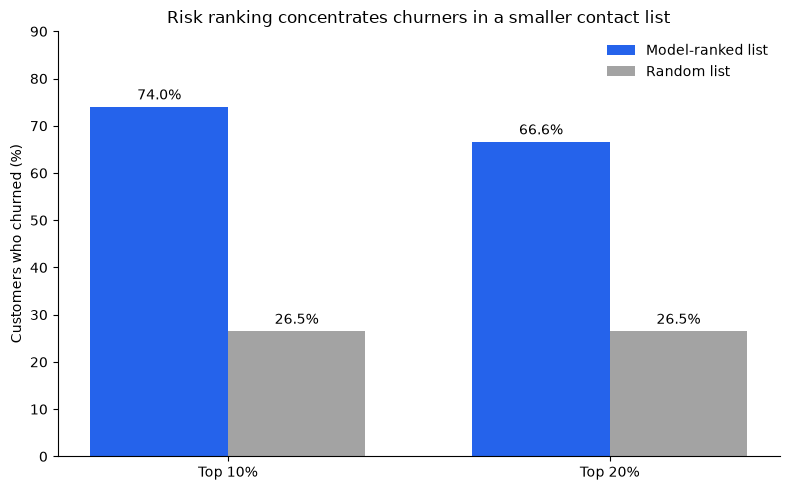

In [6]:
from pathlib import Path

plot_data = pd.DataFrame(results)
list_rates = plot_data["Churn rate in contact list"].str.rstrip("%").astype(float)
random_rate = float(
    plot_data["Random-list churn rate"].iloc[0].rstrip("%")
)

positions = np.arange(len(plot_data))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 5))
model_bars = ax.bar(
    positions - width / 2, list_rates, width,
    label="Model-ranked list", color="#2563EB"
)
random_bars = ax.bar(
    positions + width / 2, [random_rate] * len(plot_data), width,
    label="Random list", color="#A3A3A3"
)

ax.set_title("Risk ranking concentrates churners in a smaller contact list")
ax.set_ylabel("Customers who churned (%)")
ax.set_xticks(positions, plot_data["Contact capacity"])
ax.set_ylim(0, 90)
ax.legend(frameon=False)
ax.bar_label(model_bars, fmt="%.1f%%", padding=3)
ax.bar_label(random_bars, fmt="%.1f%%", padding=3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

Path("reports").mkdir(exist_ok=True)
fig.savefig("reports/churn_capacity.png", dpi=200, bbox_inches="tight")
plt.show()